# Predicting Daily Solar Energy Potential at Chengalpattu using Machine Learning
**Course:** 21CEO310T – Global Warming and Climate Change (LLT / CLA-2)
**Syllabus link:** Unit V – Mitigation (solar energy, clean technology) and Unit II – Indian climate system

**Name / Reg. No. / Department:** _fill in_

---
### Mini explanation (read this first)
Solar panels are a climate *mitigation* measure: every kWh they generate replaces a kWh from the coal-heavy grid. How much a panel produces depends on **how much sunlight reaches the ground (irradiance)**, which in turn depends on weather. If we can predict irradiance from ordinary weather variables (temperature, humidity, wind, rain), we can estimate solar output and the CO₂ it avoids.

**What this notebook does**
1. Downloads real daily weather data for Chengalpattu from **NASA POWER** (satellite + reanalysis data).
2. Checks data quality (missing values, outliers, physical limits).
3. Trains three models: **Linear Regression, Support Vector Regression (SVR), Random Forest**.
4. Evaluates them with **MAE, MSE, R²** on years the models never saw (time-based split).
5. Explains *why* the models predict what they do (coefficients, permutation importance, SHAP).
6. Converts predictions into rooftop solar energy and **CO₂ avoided**.

## 1. Setup

In [19]:
!pip install shap -q
import warnings, io
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import requests
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
sns.set_theme(style="whitegrid")

## 2. Configuration
All assumptions are in one place so you can change and justify them.
- **Location:** Chengalpattu, Tamil Nadu (approx. 12.69°N, 79.98°E).
- **Period:** 2015–2024 (10 years of daily data).
- **Split:** train on 2015–2022, test on 2023–2024.
- **PR (performance ratio):** fraction of ideal output a real rooftop system delivers after losses (typically 0.70–0.80).
- **Emission factor:** tonnes of CO₂ per MWh of Indian grid electricity. **Check the latest value in the CEA "CO₂ Baseline Database" and cite it in your report**; 0.71 is an approximate placeholder.

In [20]:
LAT, LON = 12.69, 79.98
START, END = "20150101", "20241231"
TRAIN_END_YEAR = 2022          # train: <= 2022, test: > 2022
SYSTEM_KWP = 5                 # example rooftop system size (kWp)
PERFORMANCE_RATIO = 0.75       # system losses assumption
EMISSION_FACTOR = 0.71         # tCO2 per MWh (verify with CEA and cite)
RANDOM_STATE = 42

## 3. Data source: NASA POWER
**NASA POWER** provides free daily meteorological and solar data for any coordinates. Variables used:

| Variable | Meaning | Unit |
|---|---|---|
| `ALLSKY_SFC_SW_DWN` | Solar irradiance reaching the ground (**target**) | kWh/m²/day |
| `T2M`, `T2M_MAX`, `T2M_MIN` | Air temperature at 2 m (mean / max / min) | °C |
| `RH2M` | Relative humidity | % |
| `WS2M` | Wind speed at 2 m | m/s |
| `PRECTOTCORR` | Rainfall | mm/day |

NASA marks missing values as `-999`; we convert these to `NaN` so they are not mistaken for real data.

In [21]:
def fetch_power():
    params = "ALLSKY_SFC_SW_DWN,T2M,T2M_MAX,T2M_MIN,RH2M,WS2M,PRECTOTCORR"
    url = ("https://power.larc.nasa.gov/api/temporal/daily/point"
           f"?parameters={params}&community=RE&longitude={LON}&latitude={LAT}"
           f"&start={START}&end={END}&format=JSON")
    r = requests.get(url, timeout=180)
    r.raise_for_status()
    data = r.json()["properties"]["parameter"]
    df = pd.DataFrame(data)
    df.index = pd.to_datetime(df.index, format="%Y%m%d")
    df.index.name = "date"
    return df

raw = fetch_power()
raw.to_csv("nasa_power_chengalpattu_raw.csv")   # keep a copy as evidence of the raw data
print("Downloaded:", raw.shape)
raw.head()

Downloaded: (3653, 7)


,ALLSKY_SFC_SW_DWN,T2M,T2M_MAX,T2M_MIN,RH2M,WS2M,PRECTOTCORR
date,,,,,,,
2015-01-01,2.7559,24.91,27.57,22.76,84.42,1.57,0.37
2015-01-02,4.3339,25.39,27.96,23.43,87.06,2.52,0.25
2015-01-03,4.3421,25.41,27.96,23.46,86.03,2.31,0.07
2015-01-04,4.7359,25.22,28.08,23.09,82.80,2.24,0.00
2015-01-05,4.8511,24.87,27.92,22.41,83.05,2.71,0.00


## 4. Data quality checks
Sir asked for data quality (rows and columns). We check:
- **Shape and date range** – how many rows (days) and columns (variables).
- **Missing values** – counted after converting `-999` to `NaN`.
- **Physical limits** – e.g. humidity must be 0–100 %, irradiance cannot be negative.
- **Outliers** – flagged with the IQR rule. Extreme weather (heavy rain) is real, so we *report* outliers but do not delete them blindly.

In [22]:
df = raw.replace(-999, np.nan)

print("Rows (days):", df.shape[0], "| Columns:", df.shape[1])
print("Date range :", df.index.min().date(), "to", df.index.max().date())
expected = pd.date_range(df.index.min(), df.index.max(), freq="D")
print("Missing calendar days:", len(expected.difference(df.index)))

quality = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_%": (df.isna().mean()*100).round(2),
    "min": df.min(), "mean": df.mean().round(2), "max": df.max(),
})
quality

Rows (days): 3653 | Columns: 7
Date range : 2015-01-01 to 2024-12-31
Missing calendar days: 0


,missing_count,missing_%,min,mean,max
ALLSKY_SFC_SW_DWN,0,0.0,0.2957,5.31,7.6514
T2M,0,0.0,22.2900,28.04,33.3800
T2M_MAX,0,0.0,23.5400,31.54,39.3600
T2M_MIN,0,0.0,18.8000,25.35,30.6200
RH2M,0,0.0,53.3500,74.85,93.0900
WS2M,0,0.0,0.9300,3.25,8.5700
PRECTOTCORR,0,0.0,0.0000,3.74,124.3700


In [23]:
# Physical sanity checks
checks = {
    "Irradiance < 0": (df["ALLSKY_SFC_SW_DWN"] < 0).sum(),
    "Irradiance > 10 kWh/m2/day (implausible)": (df["ALLSKY_SFC_SW_DWN"] > 10).sum(),
    "Humidity outside 0-100%": ((df["RH2M"] < 0) | (df["RH2M"] > 100)).sum(),
    "T_max < T_min": (df["T2M_MAX"] < df["T2M_MIN"]).sum(),
    "Rainfall < 0": (df["PRECTOTCORR"] < 0).sum(),
}
print(pd.Series(checks, name="violations"))

# IQR outlier report
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); i = q3 - q1
    return ((s < q1 - 1.5*i) | (s > q3 + 1.5*i)).sum()
print("\nIQR outliers per column:")
print(df.apply(iqr_outliers))

Irradiance < 0                              0
Irradiance > 10 kWh/m2/day (implausible)    0
Humidity outside 0-100%                     0
T_max < T_min                               0
Rainfall < 0                                0
Name: violations, dtype: int64

IQR outliers per column:
ALLSKY_SFC_SW_DWN     76
T2M                    0
T2M_MAX                0
T2M_MIN               41
RH2M                   0
WS2M                  49
PRECTOTCORR          407
dtype: int64


In [24]:
# Handle missing values: interpolate short gaps (<=3 days), drop anything left
before = len(df)
df = df.interpolate(limit=3, limit_direction="both").dropna()
print(f"Rows before: {before} | after cleaning: {len(df)} | dropped: {before-len(df)}")

Rows before: 3653 | after cleaning: 3653 | dropped: 0


**Why interpolate only short gaps?** Weather changes smoothly over 1–3 days, so linear interpolation is reasonable. Longer gaps would mean guessing, so those rows are dropped instead.

## 5. Exploratory analysis
Two quick plots: the seasonal pattern of sunlight (monsoon months should dip) and how variables relate to each other.

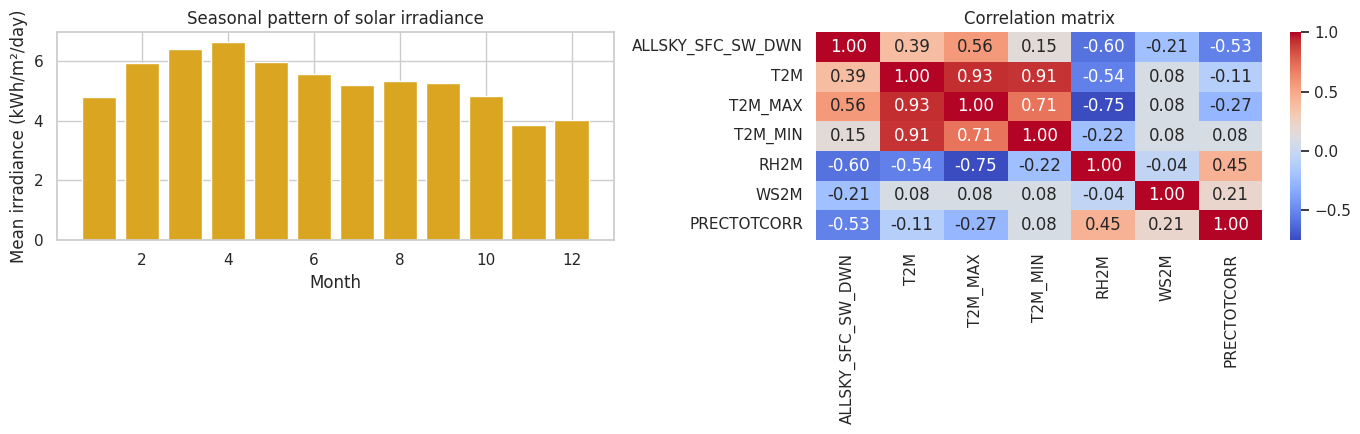

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
monthly = df["ALLSKY_SFC_SW_DWN"].groupby(df.index.month).mean()
ax[0].bar(monthly.index, monthly.values, color="goldenrod")
ax[0].set_xlabel("Month"); ax[0].set_ylabel("Mean irradiance (kWh/m²/day)")
ax[0].set_title("Seasonal pattern of solar irradiance")
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[1])
ax[1].set_title("Correlation matrix")
plt.tight_layout(); plt.show()

## 6. Feature engineering and time-based split
**Features**
- `T2M`: mean temperature.
- `T_RANGE` = `T2M_MAX` − `T2M_MIN`: a large day–night gap usually means clear skies. It acts as a cloud indicator.
- `RH2M`, `WS2M`, `PRECTOTCORR`: humidity, wind, rainfall.
- `doy_sin`, `doy_cos`: day of year encoded as a circle, so 31 Dec and 1 Jan are close together.

**Why a time-based split?** Weather on consecutive days is correlated. A random split would put neighbouring days in both train and test, leaking information and inflating scores. We train on 2015–2022 and test on 2023–2024, which mimics real forecasting.

In [26]:
data = df.copy()
data["T_RANGE"] = data["T2M_MAX"] - data["T2M_MIN"]
data["doy_sin"] = np.sin(2*np.pi*data.index.dayofyear/365.25)
data["doy_cos"] = np.cos(2*np.pi*data.index.dayofyear/365.25)

FEATURES = ["T2M", "T_RANGE", "RH2M", "WS2M", "PRECTOTCORR", "doy_sin", "doy_cos"]
TARGET = "ALLSKY_SFC_SW_DWN"

train = data[data.index.year <= TRAIN_END_YEAR]
test  = data[data.index.year >  TRAIN_END_YEAR]
X_train, y_train = train[FEATURES], train[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]
print(f"Train: {len(train)} days ({train.index.min().date()} to {train.index.max().date()})")
print(f"Test : {len(test)} days ({test.index.min().date()} to {test.index.max().date()})")

Train: 2922 days (2015-01-01 to 2022-12-31)
Test : 731 days (2023-01-01 to 2024-12-31)


## 7. Models
| Model | Idea | Why include it |
|---|---|---|
| **Baseline (climatology)** | Predict the train-set average for that day of the year | Anything useful must beat this |
| **Linear Regression** | Straight-line relationship | Simple, fully interpretable |
| **SVR** | Fits a flexible curve within a tolerance band (ε) | Handles non-linear patterns; needs scaled inputs |
| **Random Forest** | Many decision trees averaged | Captures non-linear interactions, gives feature importance |

SVR and Random Forest have settings (hyperparameters) that matter, so we tune them with `GridSearchCV` using `TimeSeriesSplit`, which always validates on data *later* than the training folds. Tuning uses only the training years, so the test set stays untouched.

In [27]:
tscv = TimeSeriesSplit(n_splits=5)

# Baseline: mean irradiance for each day-of-year in training years
clim = train.groupby(train.index.dayofyear)[TARGET].mean()
baseline_pred = test.index.dayofyear.map(clim).to_series(index=test.index).fillna(y_train.mean()).values

# Linear Regression
lr = Pipeline([("scaler", StandardScaler()), ("lr", LinearRegression())]).fit(X_train, y_train)

# SVR (scaling is essential for SVR)
svr_search = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("svr", SVR())]),
    {"svr__C": [1, 10, 50], "svr__epsilon": [0.05, 0.2], "svr__gamma": ["scale", 0.05]},
    cv=tscv, scoring="neg_mean_absolute_error", n_jobs=-1).fit(X_train, y_train)
svr = svr_search.best_estimator_

# Random Forest
rf_search = GridSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    {"n_estimators": [200, 400], "max_depth": [6, 12, None], "min_samples_leaf": [1, 5]},
    cv=tscv, scoring="neg_mean_absolute_error", n_jobs=-1).fit(X_train, y_train)
rf = rf_search.best_estimator_

print("Best SVR params:", svr_search.best_params_)
print("Best RF  params:", rf_search.best_params_)

Best SVR params: {'svr__C': 10, 'svr__epsilon': 0.2, 'svr__gamma': 0.05}
Best RF  params: {'max_depth': 12, 'min_samples_leaf': 5, 'n_estimators': 400}


## 8. Evaluation: MAE, MSE, R²
- **MAE** – average size of the error, in the same unit as the target (kWh/m²/day). Easy to interpret.
- **MSE** – average *squared* error; punishes large mistakes more. (RMSE is its square root, shown for readability.)
- **R²** – share of the variation in sunlight the model explains. 1 is perfect, 0 is no better than predicting the mean.

In [28]:
preds = {
    "Baseline (climatology)": baseline_pred,
    "Linear Regression": lr.predict(X_test),
    "SVR": svr.predict(X_test),
    "Random Forest": rf.predict(X_test),
}
rows = []
for name, p in preds.items():
    mse = mean_squared_error(y_test, p)
    rows.append({"Model": name,
                 "MAE": mean_absolute_error(y_test, p),
                 "MSE": mse, "RMSE": np.sqrt(mse),
                 "R2": r2_score(y_test, p)})
results = pd.DataFrame(rows).set_index("Model").round(3)
results

,MAE,MSE,RMSE,R2
Model,,,,
Baseline (climatology),0.788,1.047,1.023,0.414
Linear Regression,0.673,0.756,0.869,0.577
SVR,0.560,0.583,0.764,0.673
Random Forest,0.562,0.561,0.749,0.686


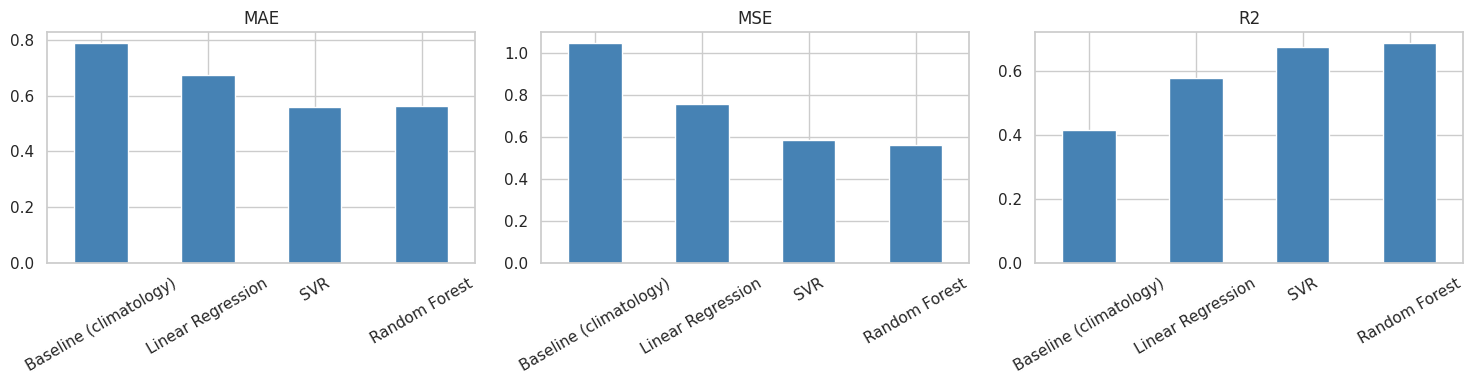

In [29]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, m in zip(ax, ["MAE", "MSE", "R2"]):
    results[m].plot.bar(ax=a, color="steelblue"); a.set_title(m); a.set_xlabel("")
    a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

**How to read this:** a useful model must have lower MAE/MSE and higher R² than the baseline. If a complex model barely beats Linear Regression, the extra complexity isn't justified. Write your actual numbers and comparison in your report.

## 9. Where do the models go wrong?
Averages can hide problems. We plot predictions against reality and check error by month.

Best model by MAE: SVR


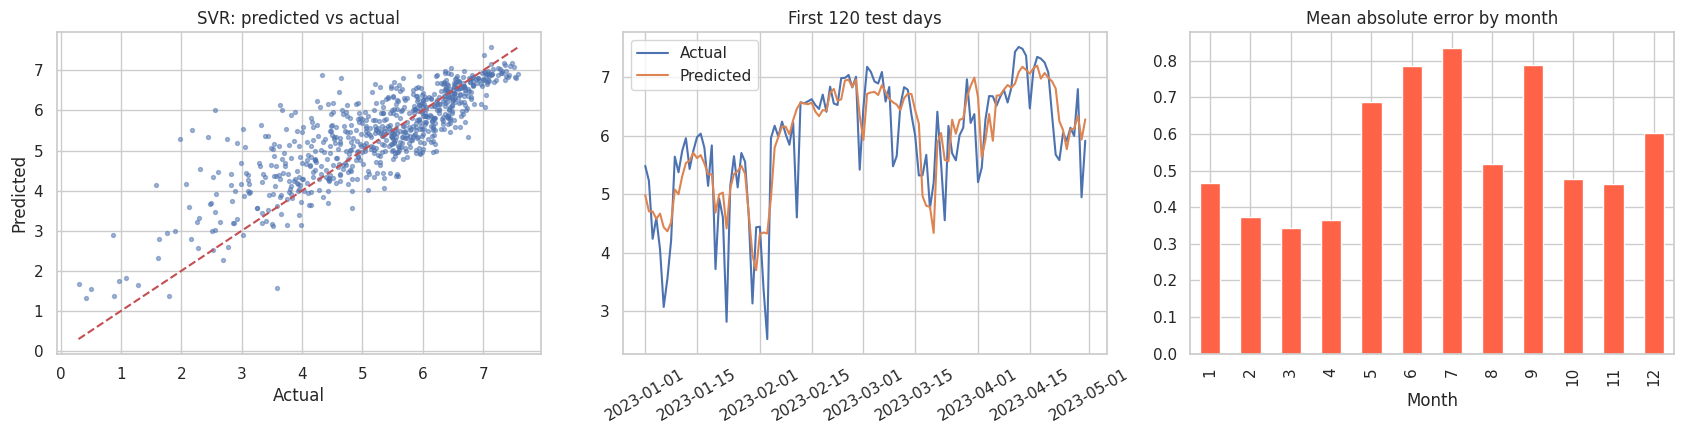

In [30]:
best_name = results["MAE"].drop("Baseline (climatology)").idxmin()
best_pred = preds[best_name]
print("Best model by MAE:", best_name)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].scatter(y_test, best_pred, s=8, alpha=0.5)
lim = [min(y_test.min(), best_pred.min()), max(y_test.max(), best_pred.max())]
ax[0].plot(lim, lim, "r--"); ax[0].set_xlabel("Actual"); ax[0].set_ylabel("Predicted")
ax[0].set_title(f"{best_name}: predicted vs actual")

zoom = slice(0, 120)
ax[1].plot(y_test.index[zoom], y_test.values[zoom], label="Actual")
ax[1].plot(y_test.index[zoom], best_pred[zoom], label="Predicted")
ax[1].set_title("First 120 test days"); ax[1].legend(); ax[1].tick_params(axis="x", rotation=30)

err = pd.Series(np.abs(y_test.values - best_pred), index=y_test.index)
err.groupby(err.index.month).mean().plot.bar(ax=ax[2], color="tomato")
ax[2].set_title("Mean absolute error by month"); ax[2].set_xlabel("Month")
plt.tight_layout(); plt.show()

**Things to comment on in your report:** Which months have the highest error? (Monsoon cloud is hardest to predict.) Does the model under- or over-predict on very bright or very cloudy days?

## 10. Explainability
The brief requires the model to be explainable. We use three complementary views:
1. **Linear Regression coefficients** – direction and strength of each feature (inputs are scaled, so coefficients are comparable).
2. **Permutation importance** – shuffle one feature on the test set and see how much the score drops; a big drop means the model relies on it.
3. **SHAP** – shows how each feature pushed each individual prediction up or down.

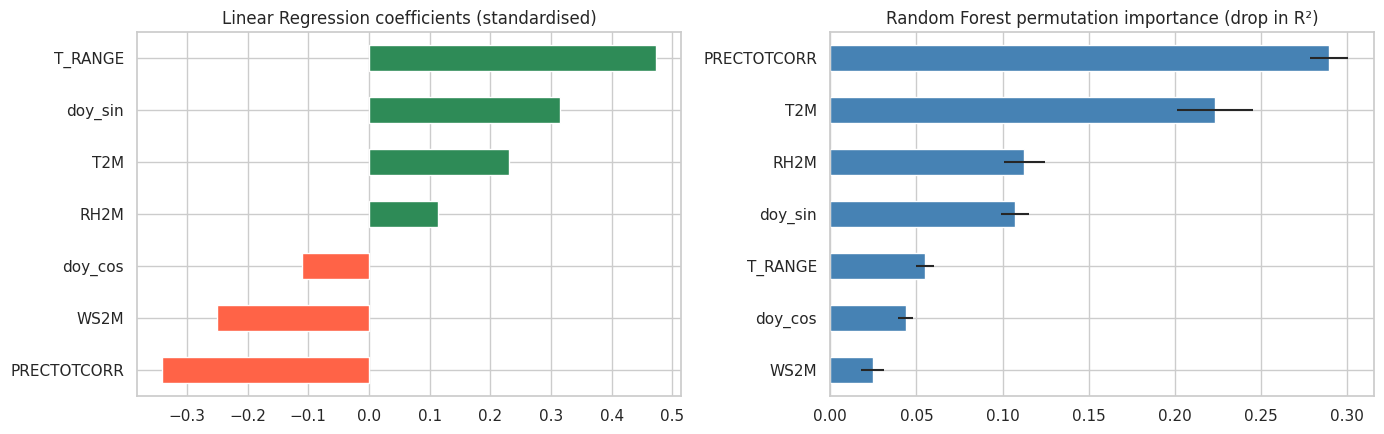

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

coef = pd.Series(lr.named_steps["lr"].coef_, index=FEATURES).sort_values()
coef.plot.barh(ax=ax[0], color=["tomato" if c < 0 else "seagreen" for c in coef])
ax[0].set_title("Linear Regression coefficients (standardised)")

perm = permutation_importance(rf, X_test, y_test, n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
pi = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
pi.plot.barh(ax=ax[1], xerr=pd.Series(perm.importances_std, index=FEATURES)[pi.index], color="steelblue")
ax[1].set_title("Random Forest permutation importance (drop in R²)")
plt.tight_layout(); plt.show()

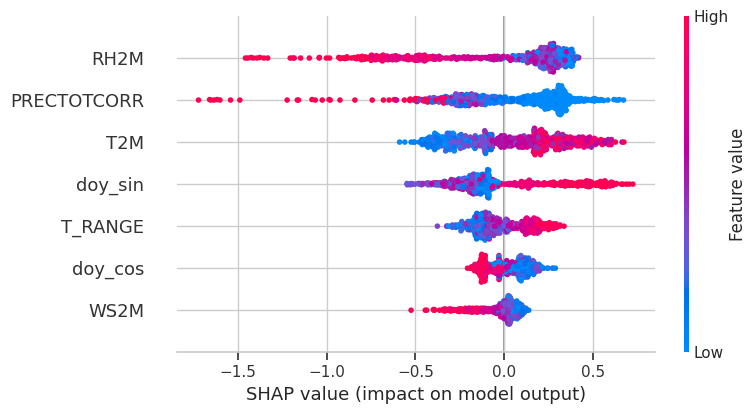

In [32]:
try:
    import shap
    explainer = shap.TreeExplainer(rf)
    shap_values = explainer.shap_values(X_test)
    shap.summary_plot(shap_values, X_test, show=True)
except Exception as e:
    print("SHAP step skipped:", e)

**Sanity check against physics:** Humidity, rainfall and a small day–night temperature range should all point to cloudier skies and therefore *lower* irradiance. If the model agrees, that's evidence it learned something physically meaningful and not noise. Note that temperature is a *proxy* for sunlight here, not its cause. Mention this distinction in your report.

## 11. Climate impact: energy generated and CO₂ avoided (Unit V)
Daily energy from a rooftop system:

`Energy (kWh) = Irradiance (kWh/m²/day) × System size (kWp) × Performance Ratio`

(Irradiance in kWh/m²/day is numerically the same as "peak sun hours", which is why this simple formula works.)
CO₂ avoided = energy generated × grid emission factor. We compute it from both the **model's predictions** and the **actual data**, so you can see whether prediction errors matter for planning.

In [ ]:
def to_energy(irr): return irr * SYSTEM_KWP * PERFORMANCE_RATIO   # kWh/day

impact = pd.DataFrame({"actual_kWh": to_energy(y_test),
                       "predicted_kWh": to_energy(pd.Series(best_pred, index=y_test.index))})
years = len(impact) / 365.25
annual_actual = impact["actual_kWh"].sum() / years
annual_pred   = impact["predicted_kWh"].sum() / years

summary = pd.DataFrame({
    "Energy (kWh/yr)": [annual_actual, annual_pred],
    "CO2 avoided (tonnes/yr)": [annual_actual/1000*EMISSION_FACTOR, annual_pred/1000*EMISSION_FACTOR],
}, index=["From actual data", f"From {best_name} prediction"]).round(1)
print(f"System: {SYSTEM_KWP} kWp | PR = {PERFORMANCE_RATIO} | EF = {EMISSION_FACTOR} tCO2/MWh")
print(f"Prediction error on annual energy: {(annual_pred-annual_actual)/annual_actual*100:+.2f}%")
summary

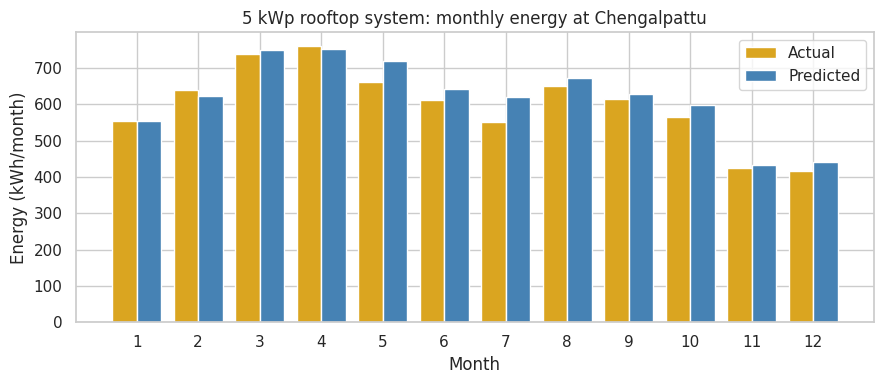

In [33]:
m = impact.groupby(impact.index.month).sum() / years
fig, ax = plt.subplots(figsize=(9, 4))
w = 0.4; x = np.arange(1, 13)
ax.bar(x - w/2, m["actual_kWh"], w, label="Actual", color="goldenrod")
ax.bar(x + w/2, m["predicted_kWh"], w, label="Predicted", color="steelblue")
ax.set_xticks(x); ax.set_xlabel("Month"); ax.set_ylabel("Energy (kWh/month)")
ax.set_title(f"{SYSTEM_KWP} kWp rooftop system: monthly energy at Chengalpattu"); ax.legend()
plt.tight_layout(); plt.show()

## 12. Limitations and conclusion
**Limitations (adapt in your own words)**
- NASA POWER values are satellite/reanalysis estimates on a coarse grid (about 0.5° × 0.5°), not readings from a ground sensor at one site.
- Only ten years of data; the test set covers just two years, so scores can vary with the years chosen.
- Features are daily averages; hour-by-hour cloud movement is not captured.
- The energy calculation uses a fixed performance ratio and ignores panel tilt, shading, dust and temperature derating.
- The emission factor is a national average and changes every year as the grid gets cleaner.

**To scale to real use:** validate against measured data from a local rooftop plant or IMD station, add forecast weather inputs for day-ahead prediction, and use hourly data.

**Conclusion template:** _State which model performed best and by how much over the baseline, which features mattered most, the estimated annual energy and CO₂ avoided for the example system, and one honest limitation._

**References to cite (verify and format properly)**
1. NASA Prediction Of Worldwide Energy Resources (POWER) – https://power.larc.nasa.gov
2. Central Electricity Authority (India), CO₂ Baseline Database for the Indian Power Sector
3. Pedregosa et al., *Scikit-learn: Machine Learning in Python*, JMLR 12, 2011
4. Lundberg & Lee, *A Unified Approach to Interpreting Model Predictions* (SHAP), NeurIPS 2017

In [35]:
!zip -r artifacts.zip artifacts
from google.colab import files
files.download("artifacts.zip")

  adding: artifacts/ (stored 0%)
  adding: artifacts/random_forest.joblib (deflated 1%)
  adding: artifacts/linear_regression.joblib (stored 0%)
  adding: artifacts/test_predictions.csv (deflated 55%)
  adding: artifacts/rf_permutation_importance.csv (deflated 27%)
  adding: artifacts/config.json (deflated 41%)
  adding: artifacts/svr.joblib (deflated 1%)
  adding: artifacts/clean_data.csv (deflated 60%)
  adding: artifacts/metrics.csv (deflated 24%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:
import joblib, json, os, sklearn
os.makedirs("artifacts", exist_ok=True)
joblib.dump(lr,  "artifacts/linear_regression.joblib", compress=3)
joblib.dump(svr, "artifacts/svr.joblib", compress=3)
joblib.dump(rf,  "artifacts/random_forest.joblib", compress=3)
data.to_csv("artifacts/clean_data.csv")
results.to_csv("artifacts/metrics.csv")
out = test[[TARGET]].copy()
for k, v in preds.items(): out[k] = v
out.to_csv("artifacts/test_predictions.csv")
pd.Series(perm.importances_mean, index=FEATURES).to_csv("artifacts/rf_permutation_importance.csv")
json.dump({"features": FEATURES, "target": TARGET, "lat": LAT, "lon": LON,
           "system_kwp": SYSTEM_KWP, "performance_ratio": PERFORMANCE_RATIO,
           "emission_factor": EMISSION_FACTOR, "best_model": best_name,
           "train_end_year": TRAIN_END_YEAR, "sklearn_version": sklearn.__version__,
           "svr_params": svr_search.best_params_, "rf_params": rf_search.best_params_},
          open("artifacts/config.json", "w"), indent=2)